# Hawkes network with delayed synapses: noise-induced rate shift and spike cross-covariance

Regenerates the delayed-Hawkes figure of the paper and every number behind it.

Two populations of an exponential Hawkes network; population $i$ fires as a Poisson process with intensity
$\lambda_i=a\,e^{v_i}$, and
$$\tau\,\dot v_i=-(v_i-E)+\sum_j W_{ij}\,(g*dN_j)(t),\qquad g(t)=\frac{t-D}{\tau_g^2}\,e^{-(t-D)/\tau_g}\,\Theta(t-D),$$
an alpha synapse delayed by $D$. Parameters: $W=\begin{pmatrix}-1&1.2\\1&-1.5\end{pmatrix}$, $E=-1$, $\tau=2$, $\tau_g=1$,
$a=1$. The mean-field rate does not depend on $D$; the loop corrections do.

**Panels.** (a) the noise-induced shift of the population-1 rate above its mean-field value $\lambda_1^*$ (the same
for every $D$) against $D$; (b), (c) the spike cross-covariance $\langle n_1(t)\,n_2(t+\tau)\rangle$ at $D=0$ and
$D=2$, tree (black) and one loop (blue) against simulation.

**Data.** `data/pipe_*.json` (pipeline) and `data/sim_*.json` (simulation) were produced by `compute.py` with
Daedalus v0.4.0. Set the flags below to `True` to regenerate them here. Costs on a laptop: the two-loop rate up to 3 min
per delay (the Padé states of the delay drive it); the one-loop cross-covariance about 25 min per delay; each
simulation under a minute. The Padé order of the delay is pinned in `compute.py` (8 for the rates, 16 for the
cross-covariance) and recorded in each data file, so the numbers do not depend on the machine.

In [1]:
%matplotlib inline
preparser(False)                     # plain Python literals in this notebook (the Sage kernel preparses by default)
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
HERE = os.path.abspath('')
sys.path[:0] = [HERE, os.path.dirname(HERE)]
import style
ROOT = style.repo_root(HERE)
import daedalus as dd
import model, compute
style.apply()
print('Daedalus', dd.__version__)

Daedalus 0.4.0


## 1. The model, typed in the SDE front end

The delay is the `delay='D'` keyword on the kernel. The pipeline replaces it by Padé states in the loops and solves
the tree level exactly.

In [2]:
print(open(os.path.join(HERE, 'model.py')).read().split('def build')[1].split('def params')[0])
dd.describe_model(model.build().build());

(delay=True):
    m = (SDE('exponential Hawkes network, delayed alpha synapses')
         .population('E', size=2)
         .parameter('Em', default=[EM, EM], indexed_by=['E'])
         .parameter('tau', default=2.0, domain='positive')
         .parameter('taug', default=1.0, domain='positive')
         .parameter('a', default=1.0, domain='positive')
         .parameter('w', default=W, indexed_by=['E', 'E']))
    if delay:
        m = m.parameter('D', default=1.0, domain='positive')
    return (m.define_kernel('g', freq_image='1/(1 + I*omega*taug)^2', **({'delay': 'D'} if delay else {}))
             .field('v', population='E')
             .point_process('n', rate='a*exp(v[i])', population='E')
             .equation('v', lhs='(tau*Dt + 1)*v[i]', rhs='Em[i] + sum(w[i,j]*Conv(g, n[j]) for j in E)'))



────────────────────────────────────────────────────────────────────────
  exponential Hawkes network, delayed alpha synapses
────────────────────────────────────────────────────────────

## 2. Pipeline and simulation data

In [3]:
RECOMPUTE_PIPELINE = False
RECOMPUTE_SIM = False
if RECOMPUTE_PIPELINE:
    for D in compute.D_RATE:
        compute.run_rate(D)
    for D in compute.D_XCOV:
        compute.run_xcov(D); compute.run_xcov(D, ell=0)
if RECOMPUTE_SIM:
    for D in compute.D_RATE:
        for dt in compute.DTS:
            compute.run_sim(D, dt)
R = {D: compute.load(f'pipe_rate_D{D:g}_ell2.json') for D in compute.D_RATE}
for D, r in R.items():
    print(f'D = {D:4g}: {r["ndiag"]} diagrams, {r["wall_s"]:6.0f} s, v{r["version"]}')

D =    0: 232 diagrams,     10 s, v0.4.0
D = 0.25: 232 diagrams,     26 s, v0.4.0
D =  0.5: 232 diagrams,     44 s, v0.4.0
D =    1: 232 diagrams,     81 s, v0.4.0
D =  1.5: 232 diagrams,    138 s, v0.4.0
D =    2: 232 diagrams,    196 s, v0.4.0


## 3. Rates

Simulation: Poisson spike counts per step, exact filter updates, a spike delay line; 1024 replicas of length 4000 at
$dt=0.005$, $0.0025$ and $0.00125$, extrapolated linearly to $dt\to0$ (weighted least squares). The exponential network
is metastable: a replica can escape to runaway firing, which the expansion (an expansion about the metastable state)
does not describe; escaped replicas are dropped and counted (`n_escaped` in the data files).

In [4]:
print(f'{"D":>5s} {"mean field":>11s} {"one loop":>9s} {"two loops":>10s} {"simulation":>14s} {"2L - sim":>10s}')
SIM = {D: compute.sim_rate(D) for D in compute.D_RATE}
print('escaped replicas:', {D: [compute.load(f'sim_D{D:g}_dt{dt:g}.json').get('n_escaped', 0) for dt in compute.DTS] for D in compute.D_RATE})
for D in compute.D_RATE:
    c = R[D]['cum']; v, e = SIM[D]
    print(f'{D:5g} {c[0]:11.4f} {c[1]:9.4f} {c[2]:10.4f} {v:9.4f}({1e4 * e:2.0f}) {(c[2] - v) / e:+8.1f} SE')
nstar = R[0.0]['cum'][0]
print('mean-field rate independent of D:', np.ptp([R[D]['cum'][0] for D in R]) < 1e-12)

    D  mean field  one loop  two loops     simulation   2L - sim
escaped replicas: {0.0: [0, 0, 0], 0.25: [0, 0, 0], 0.5: [0, 0, 0], 1.0: [0, 0, 0], 1.5: [0, 0, 0], 2.0: [0, 1, 1]}
    0      0.3747    0.3887     0.3894    0.3896( 3)     -0.7 SE
 0.25      0.3747    0.3896     0.3904    0.3905( 3)     -0.4 SE
  0.5      0.3747    0.3906     0.3916    0.3919( 3)     -1.0 SE
    1      0.3747    0.3927     0.3940    0.3944( 3)     -1.2 SE
  1.5      0.3747    0.3949     0.3967    0.3975( 3)     -2.3 SE
    2      0.3747    0.3971     0.3995    0.4007( 3)     -3.5 SE
mean-field rate independent of D: True


## 4. Spike cross-covariance

The simulator records binned rates (bin 0.1) and $C_{ij}(k)=\langle x_i(t+k)\,x_j(t)\rangle$, so the pipeline's
$\langle n_1(t)\,n_2(t+\tau)\rangle$ is $C_{21}(\tau)$ for $\tau\ge0$ and $C_{12}(|\tau|)$ for $\tau<0$.

In [5]:
def sim_xcov(D):
    runs = [compute.load(f'sim_D{D:g}_dt{dt:g}.json') for dt in compute.DTS]
    lags = np.array(runs[0]['lags'])
    C, E = compute.extrapolate([r['Cnn'] for r in runs], [r['Cnn_se'] for r in runs])
    t = np.concatenate([-lags[:0:-1], lags]); v = np.concatenate([C[0, 1][:0:-1], C[1, 0]]); e = np.concatenate([E[0, 1][:0:-1], E[1, 0]])
    return t, v, e

X = {D: compute.load(f'pipe_xcov_D{D:g}.json') for D in compute.D_XCOV}
XT = {D: compute.load(f'pipe_xcov_D{D:g}_tree.json') for D in compute.D_XCOV}
for D in compute.D_XCOV:
    t, v, e = sim_xcov(D); tau = np.array(X[D]['tau'])
    idx = [int(np.argmin(np.abs(t - x))) for x in tau]
    for l, name in ((0, 'tree'), (1, 'one loop')):
        th = sum(np.array(X[D]['by_ell'][str(k)]) for k in range(l + 1))
        print(f'D = {D:g} {name:8s}: rms deviation {np.sqrt(np.mean(((th - v[idx]) / e[idx]) ** 2)):.1f} SE over {len(tau)} lags')

D = 0 tree    : rms deviation 3.1 SE over 25 lags
D = 0 one loop: rms deviation 0.9 SE over 25 lags
D = 1 tree    : rms deviation 4.9 SE over 25 lags
D = 1 one loop: rms deviation 0.9 SE over 25 lags
D = 2 tree    : rms deviation 8.5 SE over 25 lags
D = 2 one loop: rms deviation 2.5 SE over 25 lags


## 5. The figure

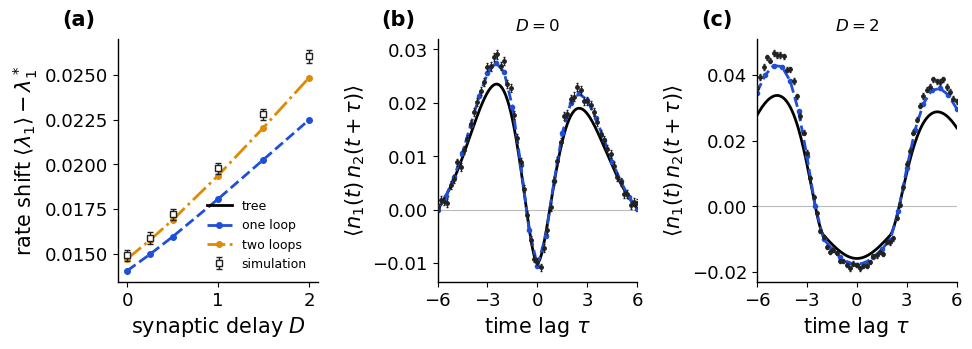

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.7))
Ds = np.array(compute.D_RATE)
ax = axes[0]
ax.plot([], [], color=style.C_TREE, lw=2.0, label='tree')
for l in (1, 2):
    c, ls, name = style.ORDER_STYLE[l]
    ax.plot(Ds, [R[D]['cum'][l] - nstar for D in Ds], color=c, ls=ls, lw=2.0, marker='o', ms=4.0, label=name)
ax.errorbar(Ds, [SIM[D][0] - nstar for D in Ds], yerr=[SIM[D][1] for D in Ds], fmt='s', color=style.C_SIM, mfc='white',
            ms=5.0, capsize=2.0, lw=1.0, label='simulation', zorder=3)
ax.set_xlabel(r'synaptic delay $D$'); ax.set_ylabel(r'rate shift $\langle\lambda_1\rangle-\lambda_1^*$')
ax.legend(frameon=False, fontsize=9, loc='lower right')
for ax, D in zip(axes[1:], (0.0, 2.0)):
    t, v, e = sim_xcov(D)
    ax.plot(XT[D]['tau'], XT[D]['by_ell']['0'], color=style.C_TREE, lw=2.0)
    one = np.array(X[D]['by_ell']['0']) + np.array(X[D]['by_ell']['1'])
    ax.plot(X[D]['tau'], one, color=style.C_L1, ls='--', lw=2.0, marker='o', ms=3.0)
    sel = np.abs(t) <= 6 + 1e-9
    ax.errorbar(t[sel][::2], v[sel][::2], yerr=e[sel][::2], fmt='o', color=style.C_SIM, ms=2.5, capsize=1.0, lw=0.8, zorder=3)
    ax.axhline(0.0, color='#bbbbbb', lw=0.8, zorder=0)
    ax.set_xlim(-6, 6); ax.set_xticks([-6, -3, 0, 3, 6]); ax.set_xlabel(r'time lag $\tau$')
    ax.set_ylabel(r'$\langle n_1(t)\,n_2(t+\tau)\rangle$'); ax.set_title(f'$D={D:g}$', fontsize=12)
style.panel_labels(axes)
fig.tight_layout()
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(HERE, f'fig_hawkes_delay.{ext}'), dpi=200)
plt.show()